# BookScrape ETL & ML Pipeline

**Missão:** Mapear os livros com os temas horror, suspense (*thriller*) e ficção científica do site: [Books to Scrape](https://books.toscrape.com/).

## Justificativa técnica da escolha

*   Ambiente controlado e estabilidade de DOM (*Document Object Model*).
*   Permite extrair e comparar atributos dos itens com clareza.
*   Não há bloqueios para *crawling*, mas será respeitado um intervalo entre as requisições (1 a 2 segundos).

# Análise do código HTML

In [1]:
import requests
from bs4 import BeautifulSoup
import json
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# Fazendo a requisição para a página de exemplo
url_exemplo = 'https://books.toscrape.com/catalogue/category/books/horror_31/index.html'
cabecalho = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'} #User-Agent

resposta = requests.get(url_exemplo, headers=cabecalho, timeout=10)
resposta.raise_for_status() # Garante que a requisição ocorreu com sucesso (HTTP 200)

# Lê sintaticamente o texto e identifica onde abrem e fecham as tags
soup = BeautifulSoup(resposta.text, 'html.parser')

primeiro_livro_html = soup.select_one('article.product_pod')
print(primeiro_livro_html.prettify())

<article class="product_pod">
 <div class="image_container">
  <a href="../../../security_925/index.html">
   <img alt="Security" class="thumbnail" src="../../../../media/cache/da/df/dadfac66a89774b46b10225362724c83.jpg"/>
  </a>
 </div>
 <p class="star-rating Two">
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
 </p>
 <h3>
  <a href="../../../security_925/index.html" title="Security">
   Security
  </a>
 </h3>
 <div class="product_price">
  <p class="price_color">
   Â£39.25
  </p>
  <p class="instock availability">
   <i class="icon-ok">
   </i>
   In stock
  </p>
  <form>
   <button class="btn btn-primary btn-block" data-loading-text="Adding..." type="submit">
    Add to basket
   </button>
  </form>
 </div>
</article>



## Mapeamento de seletores
* Elemento raiz: article.product_pod
* Título: h3 > a[title]
* Preço: div.product_price > p.price_color
* Avaliação: p.star-rating (One, Two, Three, Four, Five)
* Disponibilidade: p.instock.availability

# Fase 1: Coleta automatizada

In [2]:
import time

# 1.1. Definição dos alvos
CATEGORIAS_ALVO = {
    'Horror': 'https://books.toscrape.com/catalogue/category/books/horror_31/index.html',
    'Science Fiction': 'https://books.toscrape.com/catalogue/category/books/science-fiction_16/index.html',
    'Thriller': 'https://books.toscrape.com/catalogue/category/books/thriller_37/index.html'
}

# 1.2. Configuração do User-Agent
cabecalho = {
    'User-Agent': (
        'Mozilla/5.0 (Windows NT 10.0; Win64; x64) '
        'AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36'
    ),
    'Accept-Language': 'en-GB,en;q=0.9,pt-BR;q=0.8'
}

registros_brutos = []
id_contador = 1

print("--- INICIANDO FASE 1: CRAWLER & SCRAPING ---")

# 1.3. Iteração sobre cada categoria
for categoria, url in CATEGORIAS_ALVO.items():
    print(f"\n[+] Coletando dados da categoria: {categoria}")
    print(f"    URL: {url}")

    resposta = requests.get(url, headers=cabecalho, timeout=10)
    print(f"    Status da Conexão: {resposta.status_code}") #Verificando o status da conexão (200 = Sucesso | 403 = Bloqueado)
    resposta.raise_for_status() # Garante que a requisição ocorreu com sucesso (HTTP 200)

    # 1.4. Parsing da árvore HTML (Ler sintaticamente o texto: identificar onde abrem e fecham as tags)
    soup = BeautifulSoup(resposta.text, 'html.parser')

    # Seleciona todos os cards de livros na página
    cards_livros = soup.select('article.product_pod')
    print(f"    Livros encontrados: {len(cards_livros)}")

    # 1.5. Extração dos atributos de cada card
    for card in cards_livros:
        # A) Título completo e URL do produto
        link_tag = card.select_one('h3 > a')
        titulo = link_tag.get('title') if link_tag else None
        href = link_tag.get('href') if link_tag else ''
        # Constrói o link absoluto do livro
        url_livro = f"https://books.toscrape.com/catalogue/{href.replace('../../../', '')}"

        # B) Preço bruto (com símbolo £ e eventuais quebras de linha)
        preco_tag = card.select_one('div.product_price > p.price_color')
        preco_bruto = preco_tag.get_text() if preco_tag else None

        # C) Avaliação (Estrelas)
        estrela_tag = card.select_one('p.star-rating')
        classes_estrela = estrela_tag.get('class', []) if estrela_tag else []
        # O segundo elemento da lista representa a nota em texto (One, Two, Three, Four, Five)
        nota_texto = [c for c in classes_estrela if c != 'star-rating']
        avaliacao_bruta = nota_texto[0] if nota_texto else None

        # D) Disponibilidade em estoque
        estoque_tag = card.select_one('div.product_price > p.instock.availability')
        disponibilidade_bruta = estoque_tag.get_text() if estoque_tag else None

        # Armazena o registro bruto
        registros_brutos.append({
            'id_registro': id_contador,
            'categoria': categoria,
            'titulo_bruto': titulo,
            'preco_bruto': preco_bruto,
            'avaliacao_bruta': avaliacao_bruta,
            'disponibilidade_bruta': disponibilidade_bruta,
            'url_produto': url_livro
        })
        id_contador += 1


    # Pausa de 2 segundos antes de passar para a próxima categoria do dicionário
    print("    [⏱] Aguardando 2 segundos antes da próxima requisição...")
    time.sleep(2)

print(f"\n[✓] Coleta finalizada com sucesso! Total: {len(registros_brutos)} livros extraídos.")
print()

# 1.6. Salvamento do arquivo JSON com os dados brutos
caminho_json = 'dados_brutos_web.json'
with open(caminho_json, 'w', encoding='utf-8') as f:
    json.dump(registros_brutos, f, ensure_ascii=False, indent=2)

print(f"[✓] Arquivo '{caminho_json}' salvo com sucesso!")
print()

# 1.7. Visualização preliminar dos 5 primeiros registros brutos
df_bruto = pd.DataFrame(registros_brutos)
display(df_bruto.head(5))

--- INICIANDO FASE 1: CRAWLER & SCRAPING ---

[+] Coletando dados da categoria: Horror
    URL: https://books.toscrape.com/catalogue/category/books/horror_31/index.html
    Status da Conexão: 200
    Livros encontrados: 17
    [⏱] Aguardando 2 segundos antes da próxima requisição...

[+] Coletando dados da categoria: Science Fiction
    URL: https://books.toscrape.com/catalogue/category/books/science-fiction_16/index.html
    Status da Conexão: 200
    Livros encontrados: 16
    [⏱] Aguardando 2 segundos antes da próxima requisição...

[+] Coletando dados da categoria: Thriller
    URL: https://books.toscrape.com/catalogue/category/books/thriller_37/index.html
    Status da Conexão: 200
    Livros encontrados: 11
    [⏱] Aguardando 2 segundos antes da próxima requisição...

[✓] Coleta finalizada com sucesso! Total: 44 livros extraídos.

[✓] Arquivo 'dados_brutos_web.json' salvo com sucesso!



,id_registro,categoria,titulo_bruto,preco_bruto,avaliacao_bruta,disponibilidade_bruta,url_produto
0,1,Horror,Security,Â£39.25,Two,\n\n \n In stock\n \n,https://books.toscrape.com/catalogue/security_...
1,2,Horror,Follow You Home,Â£21.36,One,\n\n \n In stock\n \n,https://books.toscrape.com/catalogue/follow-yo...
2,3,Horror,The Loney,Â£23.40,One,\n\n \n In stock\n \n,https://books.toscrape.com/catalogue/the-loney...
3,4,Horror,Pet Sematary,Â£10.56,Three,\n\n \n In stock\n \n,https://books.toscrape.com/catalogue/pet-semat...
4,5,Horror,Doctor Sleep (The Shining #2),Â£40.12,Two,\n\n \n In stock\n \n,https://books.toscrape.com/catalogue/doctor-sl...


# Fase 2: Higienização avançada e preparação para machine learning (Model-Ready)
## 1. Carregamento dos dados

In [3]:
import re
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# 1. Carregando os dados brutos gerados na Fase 1
df_limpo = pd.read_json('dados_brutos_web.json')

print("--- DIAGNÓSTICO DOS TIPOS DE DADOS BRUTOS ---")
print(df_limpo.dtypes)

--- DIAGNÓSTICO DOS TIPOS DE DADOS BRUTOS ---
id_registro               int64
categoria                object
titulo_bruto             object
preco_bruto              object
avaliacao_bruta          object
disponibilidade_bruta    object
url_produto              object
dtype: object


## 2. Limpeza de strings e parsing de tipos

In [4]:
# 2.1. Limpeza do preço com regex robusto (Captura apenas números e ponto)
def limpar_preco(valor):
    if valor is None or pd.isna(valor):
        return np.nan

    # 2.1.1. Converte para string e troca vírgula decimal por ponto
    texto = str(valor).replace(',', '.')

    # 2.1.2. Regex (Regular Expressions) que extrai apenas a parte numérica (ex: 39.25 de "Â£39.25" ou "£ 39.25")
    # \d+ = um ou mais dígitos
    # (?:\.\d+)? = grupo opcional de ponto seguido de centavos
    resultado = re.search(r'\d+(?:\.\d+)?', texto)

    if resultado:
        return float(resultado.group(0))
    return np.nan

df_limpo['preco_gbp'] = df_limpo['preco_bruto'].apply(limpar_preco)

# 2.2. Conversão cambial: Libras (£) para Reais (R$)
TAXA_CAMBIO_GBP_BRL = 7.15  # Cotação de referência
df_limpo['preco_brl'] = (df_limpo['preco_gbp'] * TAXA_CAMBIO_GBP_BRL).round(2)

# 2.3. Mapeamento ordinal da avaliação (Transforma texto em número inteiro)
MAPA_ESTRELAS = {
    'One': 1,
    'Two': 2,
    'Three': 3,
    'Four': 4,
    'Five': 5
}
df_limpo['avaliacao_num'] = df_limpo['avaliacao_bruta'].map(MAPA_ESTRELAS)

# 2.4. Limpeza da disponibilidade: cria variável binária (1 = Disponível, 0 = Esgotado)
df_limpo['em_estoque'] = df_limpo['disponibilidade_bruta'].astype(str).str.contains('In stock', case=False).astype(int)

# 2.5. Limpeza de título: remove espaços nas extremidades
df_limpo['titulo_limpo'] = df_limpo['titulo_bruto'].astype(str).str.strip()

## 3. Tratamento de Missing Data
Como a amostra não contém valores faltantes ou nulos, para fins didáticos foram inseridos 2 valores nulos de forma controlada.

In [5]:
# 3.1. Simulação de 2 valores nulos controlados, um no preço e um na avaliação
df_limpo.loc[df_limpo['id_registro'] == 3, 'preco_gbp'] = np.nan
df_limpo.loc[df_limpo['id_registro'] == 7, 'avaliacao_num'] = np.nan

print("Valores Nulos detectados antes da Imputação:")
print(df_limpo[['preco_gbp', 'avaliacao_num', 'categoria']].isnull().sum())
print()

# A) Imputação por Mediana na variável contínua (robusta contra valores extremos)
mediana_preco = round(df_limpo['preco_gbp'].median(), 2)
df_limpo['preco_gbp'].fillna(mediana_preco, inplace=True)
# Recalcula o preço em reais para o registro imputado
df_limpo['preco_brl'] = (df_limpo['preco_gbp'] * TAXA_CAMBIO_GBP_BRL).round(2)

# B) Imputação por Moda na variável discreta/ordinal
moda_avaliacao = df_limpo['avaliacao_num'].mode()[0]
df_limpo['avaliacao_num'].fillna(moda_avaliacao, inplace=True)

print("Valores Nulos após a Imputação (Tratamento concluído):")
print(df_limpo[['preco_gbp', 'avaliacao_num', 'categoria']].isnull().sum())

Valores Nulos detectados antes da Imputação:
preco_gbp        1
avaliacao_num    1
categoria        0
dtype: int64

Valores Nulos após a Imputação (Tratamento concluído):
preco_gbp        0
avaliacao_num    0
categoria        0
dtype: int64


## 4. Normalização / Escalonamento (Feature scaling)

In [6]:
colunas_para_escalonar = ['preco_gbp', 'avaliacao_num']

# 4.1. StandardScaler (Z-Score: média = 0, desvio padrão = 1)
scaler_std = StandardScaler()
valores_std = scaler_std.fit_transform(df_limpo[colunas_para_escalonar])

df_limpo['preco_zscore'] = np.round(valores_std[:, 0], 4)
df_limpo['avaliacao_zscore'] = np.round(valores_std[:, 1], 4)

# 4.2. MinMaxScaler (Escala linear entre 0.0 e 1.0)
scaler_minmax = MinMaxScaler()
valores_minmax = scaler_minmax.fit_transform(df_limpo[colunas_para_escalonar])

df_limpo['preco_minmax'] = np.round(valores_minmax[:, 0], 4)
df_limpo['avaliacao_minmax'] = np.round(valores_minmax[:, 1], 4)

## 5. Discretização de dados (Binning)
Transformar variáveis numéricas contínuas em categorias.

In [7]:
# 5.1. pd.qcut: Discretização (Barato, Médio, Caro)
df_limpo['faixa_preco'] = pd.qcut(
    df_limpo['preco_gbp'],
    q=3,
    labels=['Barato', 'Médio', 'Caro'],
    duplicates='drop'
).astype(str)

# 5.2. pd.cut: Discretização por limites fixos de popularidade/nota
# 1 a 2 estrelas = Baixa | 3 estrelas = Moderada | 4 a 5 estrelas = Alta
df_limpo['nivel_popularidade'] = pd.cut(
    df_limpo['avaliacao_num'],
    bins=[0, 2, 3, 5],
    labels=['Baixa', 'Moderada', 'Alta'],
    include_lowest=True
).astype(str)

# Fase 3: Exportação e integração

## 1. Exportação do dataset final higienizado e tratado

In [8]:
colunas_finais = [
    'id_registro', 'categoria', 'titulo_limpo', 'preco_gbp', 'preco_brl',
    'avaliacao_num', 'em_estoque', 'preco_zscore', 'preco_minmax',
    'avaliacao_zscore', 'avaliacao_minmax', 'faixa_preco', 'nivel_popularidade'
]

df_modelo_pronto = df_limpo[colunas_finais]

# Salva o arquivo .CSV com os dados finais tratados
caminho_csv = 'dados_modelo_pronto.csv'
df_modelo_pronto.to_csv(caminho_csv, index=False, encoding='utf-8')

print(f"[✓] Arquivo '{caminho_csv}' exportado com sucesso!")
print(f"    Dimensões finais: {df_modelo_pronto.shape[0]} linhas x {df_modelo_pronto.shape[1]} colunas.\n")

display(df_modelo_pronto.head(5))

[✓] Arquivo 'dados_modelo_pronto.csv' exportado com sucesso!
    Dimensões finais: 44 linhas x 13 colunas.



,id_registro,categoria,titulo_limpo,preco_gbp,preco_brl,avaliacao_num,em_estoque,preco_zscore,preco_minmax,avaliacao_zscore,avaliacao_minmax,faixa_preco,nivel_popularidade
0,1,Horror,Security,39.25,280.64,2.0,1,0.3514,0.5837,-0.3881,0.25,Médio,Baixa
1,2,Horror,Follow You Home,21.36,152.72,1.0,1,-0.9233,0.2197,-1.0996,0.00,Barato,Baixa
2,3,Horror,The Loney,35.63,254.75,1.0,1,0.0935,0.5101,-1.0996,0.00,Médio,Baixa
3,4,Horror,Pet Sematary,10.56,75.50,3.0,1,-1.6928,0.0000,0.3234,0.50,Barato,Moderada
4,5,Horror,Doctor Sleep (The Shining #2),40.12,286.86,2.0,1,0.4134,0.6014,-0.3881,0.25,Caro,Baixa


## 2. Disponibilização dos dados via API REST

In [9]:
%%writefile api.py

from fastapi import FastAPI, Query
from typing import Optional
import pandas as pd

# 1. Inicialização da aplicação FastAPI com metadados para a documentação
app = FastAPI(
    title="Books Analytics & ML-Ready API",
    description="API REST para consulta de livros das categorias Horror, Science Fiction e Thriller.",
    version="1.0.0"
)

# 2. Função auxiliar para carregar o arquivo .CSV gerado
def carregar_dados():
    return pd.read_csv("dados_modelo_pronto.csv")

# 3. Endpoint raiz de verificação de saúde (Health Check)
@app.get("/")
def home():
    return {
        "mensagem": "API ML-Ready ativa! Acesse /dados para consumir o dataset ou /docs para testar."
    }

# 4. Endpoint principal: GET /dados
# Permite filtros opcionais via URL (ex: /dados?categoria=Horror&faixa_preco=Barato)
@app.get("/dados")
def listar_dados(
    categoria: Optional[str] = Query(None, description="Filtrar por categoria (ex: Horror, Science Fiction, Thriller)"),
    faixa_preco: Optional[str] = Query(None, description="Filtrar por faixa (Barato, Médio, Caro)"),
    limite: int = Query(50, ge=1, le=100, description="Quantidade máxima de registros retornados")
):
    # Carrega o dataframe limpo
    df = carregar_dados()

    # Aplica filtros se o usuário/sistema tiver passado na URL
    if categoria:
        df = df[df["categoria"].str.lower() == categoria.lower()]
    if faixa_preco:
        df = df[df["faixa_preco"].str.lower() == faixa_preco.lower()]

    # Converte o resultado filtrado para lista de dicionários (formato JSON)
    registros = df.head(limite).to_dict(orient="records")

    return {
        "status": "sucesso",
        "total_retornado": len(registros),
        "filtros": {"categoria": categoria, "faixa_preco": faixa_preco},
        "dados": registros
    }

Writing api.py


## Teste do endpoint GET /dados diretamente no Notebook (sem precisar subir servidor)

In [10]:
from fastapi.testclient import TestClient
from api import app
import json

cliente = TestClient(app)

# Faz uma requisição simulada para GET /dados filtrando por Horror
resposta_api = cliente.get("/dados?categoria=Thriller&faixa_preco=caro&limite=10")

print(f"Status HTTP: {resposta_api.status_code}")
print("Resposta JSON do endpoint GET /dados:")
print(json.dumps(resposta_api.json(), indent=2, ensure_ascii=False))

Status HTTP: 200
Resposta JSON do endpoint GET /dados:
{
  "status": "sucesso",
  "total_retornado": 3,
  "filtros": {
    "categoria": "Thriller",
    "faixa_preco": "caro"
  },
  "dados": [
    {
      "id_registro": 36,
      "categoria": "Thriller",
      "titulo_limpo": "Behind Closed Doors",
      "preco_gbp": 52.22,
      "preco_brl": 373.37,
      "avaliacao_num": 4.0,
      "em_estoque": 1,
      "preco_zscore": 1.2756,
      "preco_minmax": 0.8476,
      "avaliacao_zscore": 1.035,
      "avaliacao_minmax": 0.75,
      "faixa_preco": "Caro",
      "nivel_popularidade": "Alta"
    },
    {
      "id_registro": 37,
      "categoria": "Thriller",
      "titulo_limpo": "You (You #1)",
      "preco_gbp": 43.61,
      "preco_brl": 311.81,
      "avaliacao_num": 5.0,
      "em_estoque": 1,
      "preco_zscore": 0.6621,
      "preco_minmax": 0.6724,
      "avaliacao_zscore": 1.7465,
      "avaliacao_minmax": 1.0,
      "faixa_preco": "Caro",
      "nivel_popularidade": "Alta"
    },
 

# Fase 4: Análises gráficas
## 1. Histograma
Comprovação visual dos dados antes e depois da normalização e escalonamento.

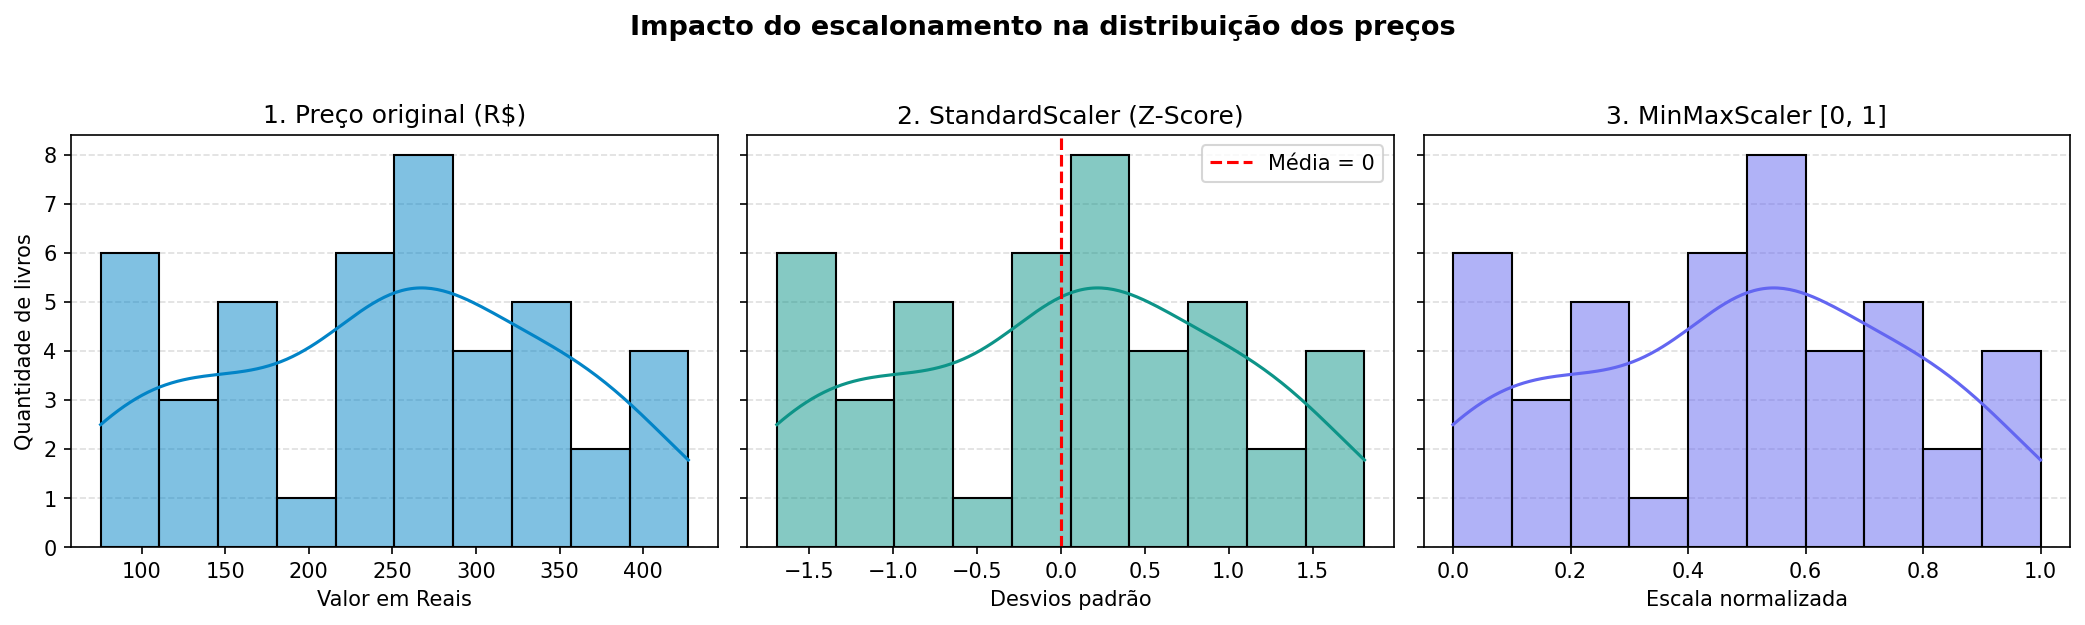

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("dados_modelo_pronto.csv")

fig, axes = plt.subplots(1, 3, figsize=(14, 4), dpi=150, sharey=True)

# Gráfico 1: Escala original (Reais)
sns.histplot(df['preco_brl'], bins=10, kde=True, ax=axes[0], color='#0284c7')
axes[0].set_title("1. Preço original (R$)")
axes[0].set_xlabel("Valor em Reais")
axes[0].set_ylabel("Quantidade de livros")  # Rótulo apenas no gráfico da esquerda

# Gráfico 2: StandardScaler (Z-Score: média 0, desvio 1)
sns.histplot(df['preco_zscore'], bins=10, kde=True, ax=axes[1], color='#0d9488')
axes[1].axvline(0, color='red', linestyle='--', label='Média = 0')
axes[1].set_title("2. StandardScaler (Z-Score)")
axes[1].set_xlabel("Desvios padrão")
axes[1].set_ylabel("")  # Remove o label padrão
axes[1].legend()

# Gráfico 3: MinMaxScaler (Intervalo [0, 1])
sns.histplot(df['preco_minmax'], bins=10, kde=True, ax=axes[2], color='#6366f1')
axes[2].set_title("3. MinMaxScaler [0, 1]")
axes[2].set_xlabel("Escala normalizada")
axes[2].set_ylabel("")  # Remove o label padrão

# Aplica linhas finas horizontais nos 3 gráficos atrás das barras
for ax in axes:
    ax.grid(axis='y', linestyle='--', alpha=0.4, linewidth=0.8)
    ax.set_axisbelow(True)

plt.suptitle("Impacto do escalonamento na distribuição dos preços", fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

### Análise
Os três histogramas apresentam exatamente o mesmo perfil de distribuição e altura das barras, alterando apenas os valores do eixo horizontal:
* O **`StandardScaler`** centralizou os preços em torno da média **0**, variando aproximadamente entre **-1,7** e **+2,0** desvios padrão.
* O **`MinMaxScaler`** comprimiu todos os registros proporcionalmente para o intervalo fechado **[0, 1]**.

Isso mostra visualmente que o escalonamento colocou as variáveis na mesma grandeza numérica.

## 2. Matriz de correlação de Pearson (Heatmap)

Objetivo: Investigar se existe relação linear entre o preço dos livros e a nota de avaliação, além de comprovar que a normalização preservou a distribuição original.

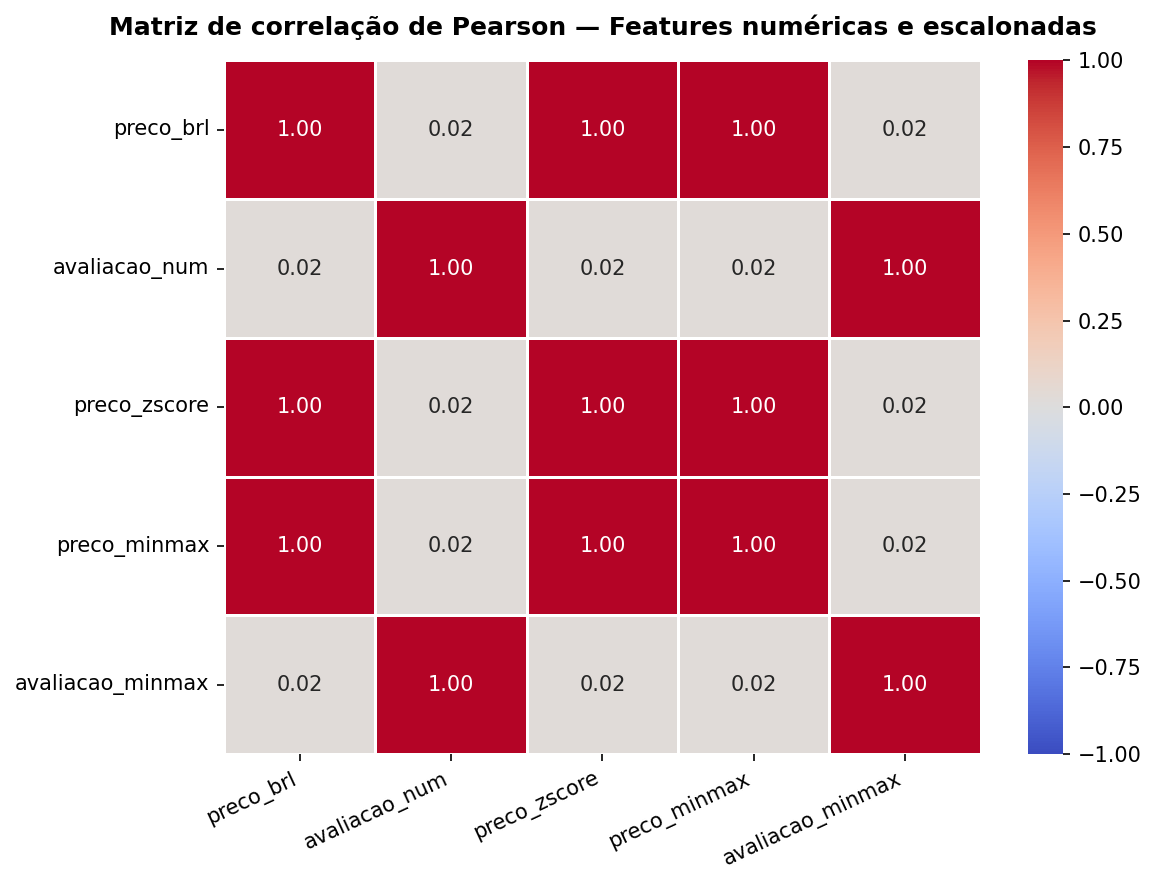

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Carrega o dataset limpo gerado na Fase 2
df = pd.read_csv('dados_modelo_pronto.csv')

# Seleciona apenas as colunas numéricas relevantes para a correlação
colunas_corr = [
    'preco_brl', 'avaliacao_num',
    'preco_zscore', 'preco_minmax', 'avaliacao_minmax'
]

# Calcula a matriz de correlação de Pearson
matriz_corr = df[colunas_corr].corr()

plt.figure(figsize=(8, 6), dpi=150)
sns.heatmap(
    matriz_corr,
    annot=True,           # Mostra os valores dentro dos quadrados
    fmt=".2f",            # 2 casas decimais
    cmap="coolwarm",      # Paleta de cores (Azul=Negativo, Vermelho=Positivo)
    vmin=-1, vmax=1,      # Escala fixa de -1 a +1
    linewidths=0.5
)
plt.title("Matriz de correlação de Pearson — Features numéricas e escalonadas", fontsize=12, fontweight='bold', pad=12)
plt.xticks(rotation=25, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Análise
A correlação exata de `1.00` entre `preco_brl`, `preco_zscore` e `preco_minmax` comprova que o escalonamento não distorceu os dados. Já a correlação próxima de zero entre preço e avaliação mostra que livros mais caros não recebem notas melhores no catálogo analisado.

## 3. Comparação de preços por categoria (Boxplot)

Objetivo: Descobrir se existe alguma categoria que é mais cara, qual categoria tem maior variação de preços e se existem valores extremos (outliers).

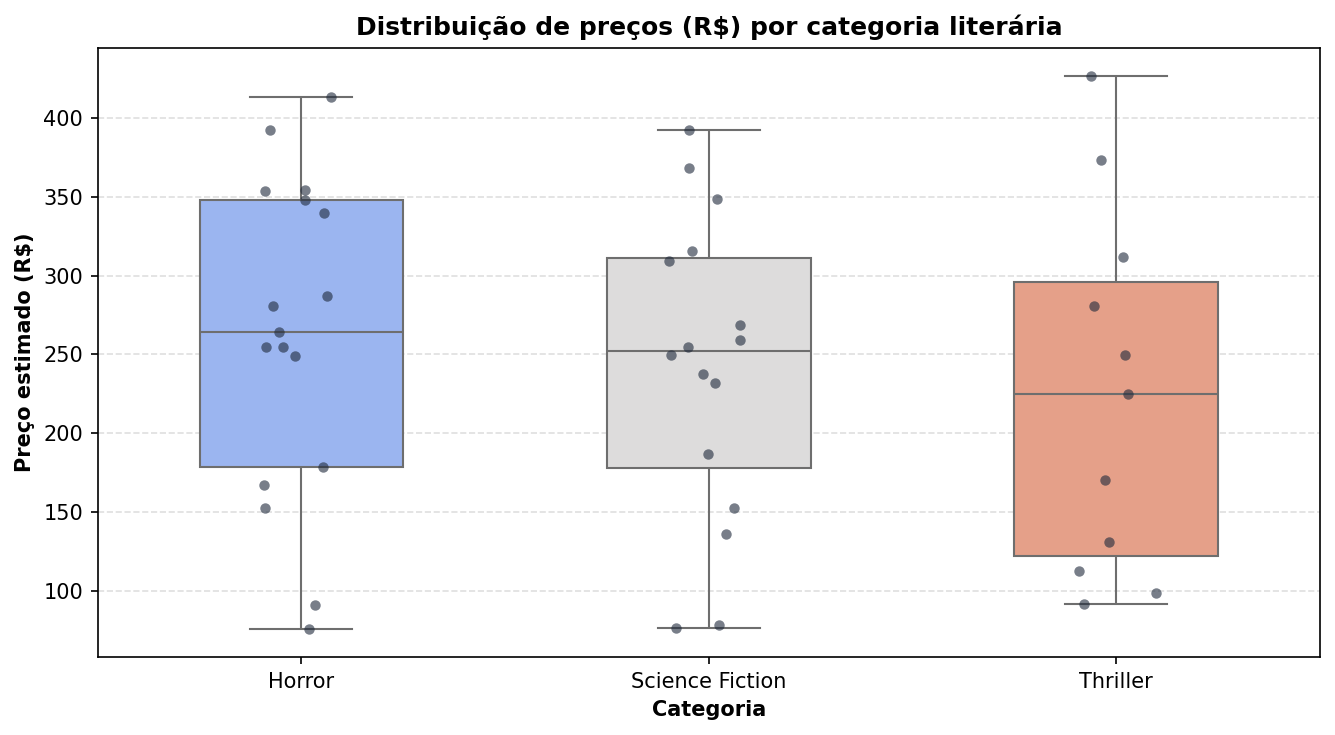

,Qtd. Livros,Média (R$),Desvio Padrão,Mínimo (R$),Q1 (25%),Mediana (50%),Q3 (75%),Máximo (R$)
categoria,,,,,,,,
Horror,17,R$ 262.18,R$ 101.07,R$ 75.50,R$ 178.82,R$ 264.34,R$ 347.78,R$ 413.70
Science Fiction,16,R$ 241.69,R$ 95.84,R$ 76.15,R$ 178.25,R$ 252.50,R$ 311.16,R$ 392.25
Thriller,11,R$ 224.75,R$ 114.94,R$ 91.81,R$ 121.88,R$ 225.15,R$ 296.19,R$ 426.93


In [13]:
plt.figure(figsize=(9, 5), dpi=150)

sns.boxplot(
    data=df,
    x='categoria',
    y='preco_brl',
    palette='coolwarm',
    width=0.5
)
# Adiciona os pontos individuais por cima do boxplot
sns.stripplot(
    data=df,
    x='categoria',
    y='preco_brl',
    color='#1e293b',
    alpha=0.6,
    size=5
)

plt.title("Distribuição de preços (R$) por categoria literária", fontsize=12, fontweight='bold')
plt.xlabel("Categoria", fontweight='bold')
plt.ylabel("Preço estimado (R$)", fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

print()
print()
print()

# TABELA COM VALORES PARA COMPLEMENTAR O BOXSPLOT

import matplotlib.cm as cm
import matplotlib.colors as mcolors

# Cores derivadas do tema coolwarm para manter unidade com o boxsplot
fundo_azul_suave = mcolors.to_hex(cm.coolwarm(0.25))      # Azul claro
fundo_vermelho_suave = mcolors.to_hex(cm.coolwarm(0.75))  # Vermelho/salmão claro

# Calcula o resumo e traduz as colunas para português
resumo_stats = df.groupby('categoria')['preco_brl'].describe().round(2)
resumo_stats.columns = [
    'Qtd. Livros', 'Média (R$)', 'Desvio Padrão',
    'Mínimo (R$)', 'Q1 (25%)', 'Mediana (50%)', 'Q3 (75%)', 'Máximo (R$)'
]

# Estilização com destaque pontual de Máximo e Mínimo
tabela_estilizada = (
    resumo_stats.style
    .format({
        'Qtd. Livros': '{:.0f}',
        'Média (R$)': 'R$ {:.2f}',
        'Desvio Padrão': 'R$ {:.2f}',
        'Mínimo (R$)': 'R$ {:.2f}',
        'Q1 (25%)': 'R$ {:.2f}',
        'Mediana (50%)': 'R$ {:.2f}',
        'Q3 (75%)': 'R$ {:.2f}',
        'Máximo (R$)': 'R$ {:.2f}'
    })
    .set_table_styles([
        {'selector': 'th.col_heading', 'props': [('background-color', '#1e293b'), ('color', 'white'), ('font-weight', 'bold'), ('padding', '8px 10px'), ('text-align', 'center')]},
        {'selector': 'th.row_heading', 'props': [('background-color', '#f8fafc'), ('color', '#1e293b'), ('font-weight', 'bold'), ('padding', '8px 12px')]},
        {'selector': 'td', 'props': [('padding', '8px 12px'), ('text-align', 'right'), ('border-bottom', '1px solid #e2e8f0')]},
        {'selector': 'caption', 'props': [('font-size', '15px'), ('font-weight', 'bold'), ('color', '#0f172a'), ('margin-bottom', '10px'), ('text-align', 'center')]}
    ])
    # Destaca APENAS o maior valor da coluna 'Máximo (R$)'
    .highlight_max(
        subset=['Máximo (R$)'],
        props=f'background-color: {fundo_vermelho_suave}; color: #000000; font-weight: bold; border-radius: 4px;'
    )
    # Destaca APENAS o menor valor da coluna 'Mínimo (R$)' em azul coolwarm
    .highlight_min(
        subset=['Mínimo (R$)'],
        props=f'background-color: {fundo_azul_suave}; color: #000000; font-weight: bold; border-radius: 4px;'
    )

    # Destaca a coluna Mediana inteira com tom neutro suave e negrito
    .set_properties(
        subset=['Mediana (50%)'],
        **{'background-color': '#ccf0d0', 'font-weight': 'bold', 'color': '#000000'}
    )
    .set_caption("Resumo estatístico de preços (R$) por categoria literária")
)

display(tabela_estilizada)

### Análise
A categoria Horror apresenta o maior preço mediano do catálogo, R\$ 264,34, seguida por Science Fiction, R\$ 252,50. Thriller concentra a menor mediana entre os três gêneros, R\$ 225,15, sendo a categoria com tendência central mais acessível.

Das 3 categorias analisadas, Science Fiction tem a menor variabilidade no valor dos títulos, aproximadamente entre R\$ 180 e R\$ 310.

A categoria Horror concentra um grande volume de livros na metade superior da distribuição, com valores R\$ 250 e R\$ 355. Das 3 categorias, possui também o item com menor valor, R\$ 75,50.

Thriller apresenta a maior amplitude total e uma dispersão acentuada nos preços, tendo também o livro mais caro, de R\$ 426,93.

Nas 3 categorias analisadas, não existem valores extremos (outliers).

## 4. Análise da discretização
Gráfico cruzando a faixa de preço e o nível de popularidade.

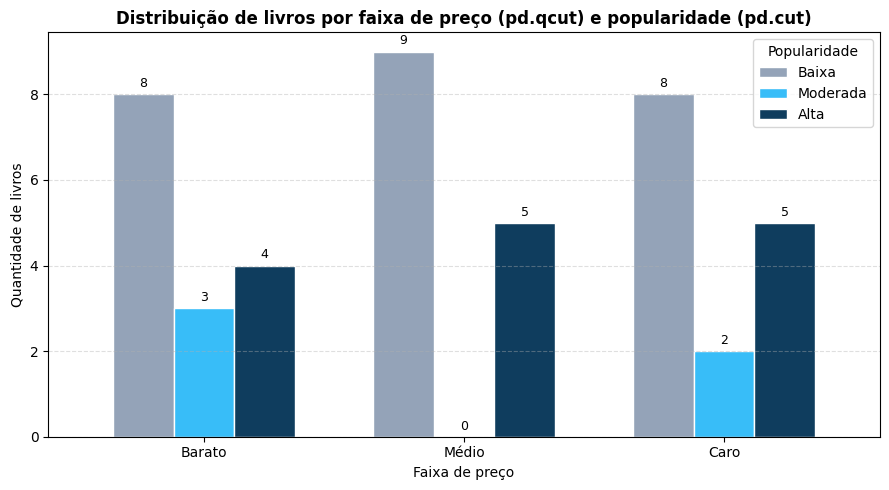

In [14]:
# Cria uma tabela cruzada ordenada
tabela_cruzada = pd.crosstab(df['faixa_preco'], df['nivel_popularidade']).reindex(
    index=['Barato', 'Médio', 'Caro'],
    columns=['Baixa', 'Moderada', 'Alta'],
    fill_value=0
)

ax = tabela_cruzada.plot(
    kind='bar',
    figsize=(9, 5),
    color=['#94a3b8', '#38bdf8', '#0f3d5e'],
    edgecolor='white',
    width=0.7
)

# Adiciona os números exatos em cima de cada barra
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=9)

plt.title("Distribuição de livros por faixa de preço (pd.qcut) e popularidade (pd.cut)", fontsize=12, fontweight='bold')
plt.xlabel("Faixa de preço")
plt.ylabel("Quantidade de livros")
plt.xticks(rotation=0)
plt.legend(title="Popularidade")
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### Análise
A discretização quantílica (`pd.qcut`) dividiu os 44 livros de forma balanceada em três faixas de valor (**Barato**: 15 livros, **Médio**: 14 livros e **Caro**: 15 livros).

Esse equilíbrio reforça o resultado da matriz de correlação, livros mais caros não garantem avaliações melhores no catálogo analisado.

# Conclusão Geral
O pipeline desenvolvido cumpriu todas as etapas de ponta a ponta da engenharia de dados para machine learning:
* **Coleta:** Extração automatizada de 44 livros das categorias *Horror* (17), *Science Fiction* (16) e *Thriller* (11) no portal *Books to Scrape*, respeitando intervalos entre requisições e persistindo o histórico bruto em `dados_brutos_web.json`.
* **Higienização e feature engineering:** Remoção de ruídos de codificação via regex (*Regular Expressions*), conversão cambial (£ para R\$), tratamento de valores nulos por mediana e moda, escalonamento (`StandardScaler` e `MinMaxScaler`) e discretização (`pd.qcut` e `pd.cut`), gerando o dataset final `dados_modelo_pronto.csv` com 44 linhas e 13 colunas.
* **Integração e análise:** Disponibilização dos dados tratados via API REST com **FastAPI** (`GET /dados` com filtros dinâmicos e validação HTTP 200) e análise exploratória completa, demonstrando que **Horror** possui a maior mediana de preços (R\$ 264,34) e **Thriller** a maior amplitude (de R\$ 91,81 a R\$ 426,93), sem correlação linear entre preço e avaliação.